# News sentiment analyzer: dictionaries vs. a trained model
**Stephanie Kim** · [Project page](https://stephaniekim62-cpu.github.io/projects/sentiment.html)

**Question:** can we tell whether a financial news sentence is good, bad or neutral for investors, and do off-the-shelf sentiment dictionaries work for this?

**Data:** the Financial PhraseBank (Malo et al., 2014). It has 4,846 sentences from financial news, each labeled by 5–8 finance-trained annotators. I use the version where at least 50% of annotators agreed. License: CC BY-NC-SA 3.0.

In [1]:
!pip -q install vaderSentiment pysentiment2

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, urllib.request, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

URL = "https://raw.githubusercontent.com/Kapilgwal/NLP-APPLICATION/main/"   # public mirror of the PhraseBank files
def load(fname):
    lines = urllib.request.urlopen(URL + fname).read().decode("latin-1").splitlines()
    return pd.DataFrame([l.rsplit("@", 1) for l in lines if "@" in l], columns=["text", "label"]).drop_duplicates("text")

df = load("Sentences_50Agree.txt")
all_agree = set(load("Sentences_AllAgree.txt").text)
print(len(df), "sentences"); df.label.value_counts()

4838 sentences


label
neutral     2872
positive    1362
negative     604
Name: count, dtype: int64

In [3]:
df.sample(5, random_state=1)

,text,label
2703,"We know that it exists , '' Artemyev said .",neutral
4144,`` My wife is looking forward to getting a pay...,neutral
502,"Ruukki 's delivery includes steel structures ,...",neutral
3198,The company 's board of directors would propos...,neutral
1275,"KONE , headquartered in Espoo , Finland , is o...",neutral


## 1. Train/test split
Stratified 80/20 with a fixed seed, so every model is scored on the same 968 unseen sentences.

In [4]:
train, test = train_test_split(df, test_size=0.2, stratify=df.label, random_state=42)
labels = ["negative", "neutral", "positive"]
results = []
def evaluate(name, pred):
    results.append({"Model": name, "Accuracy": accuracy_score(test.label, pred), "Macro F1": f1_score(test.label, pred, average="macro")})
evaluate("Always 'neutral' (baseline)", ["neutral"] * len(test))

## 2. Off-the-shelf dictionaries
- **VADER:** a general-purpose lexicon built for social media.
- **Loughran–McDonald:** a finance-specific word list built from 10-K filings.

In [5]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pysentiment2 as ps
vader = SentimentIntensityAnalyzer()
def vader_label(t):
    s = vader.polarity_scores(t)["compound"]
    return "positive" if s >= 0.05 else "negative" if s <= -0.05 else "neutral"
lm = ps.LM()
def lm_label(t):
    s = lm.get_score(lm.tokenize(t))["Polarity"]
    return "positive" if s > 0.1 else "negative" if s < -0.1 else "neutral"
evaluate("VADER (general)", [vader_label(t) for t in test.text])
evaluate("Loughran–McDonald (finance)", [lm_label(t) for t in test.text])
pd.DataFrame(results)

,Model,Accuracy,Macro F1
0,Always 'neutral' (baseline),0.594008,0.248434
1,VADER (general),0.537190,0.492986
2,Loughran–McDonald (finance),0.578512,0.469337


Both dictionaries score **below the always-neutral baseline** on accuracy. Words like *increase* or *rose* carry no tone in a word list, but they're usually good news in an earnings sentence.

## 3. Trained model: TF-IDF + logistic regression

In [6]:
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=4000)
X_train, X_test = vec.fit_transform(train.text), vec.transform(test.text)
clf = LogisticRegression(max_iter=2000, C=8, class_weight="balanced").fit(X_train, train.label)
pred = clf.predict(X_test)
evaluate("TF-IDF + logistic regression", pred)
pd.DataFrame(results).style.format({"Accuracy": "{:.1%}", "Macro F1": "{:.2f}"})

,Model,Accuracy,Macro F1
0,Always 'neutral' (baseline),59.4%,0.25
1,VADER (general),53.7%,0.49
2,Loughran–McDonald (finance),57.9%,0.47
3,TF-IDF + logistic regression,73.7%,0.69


Accuracy on the 459 test sentences that every annotator agreed on: 86.7%


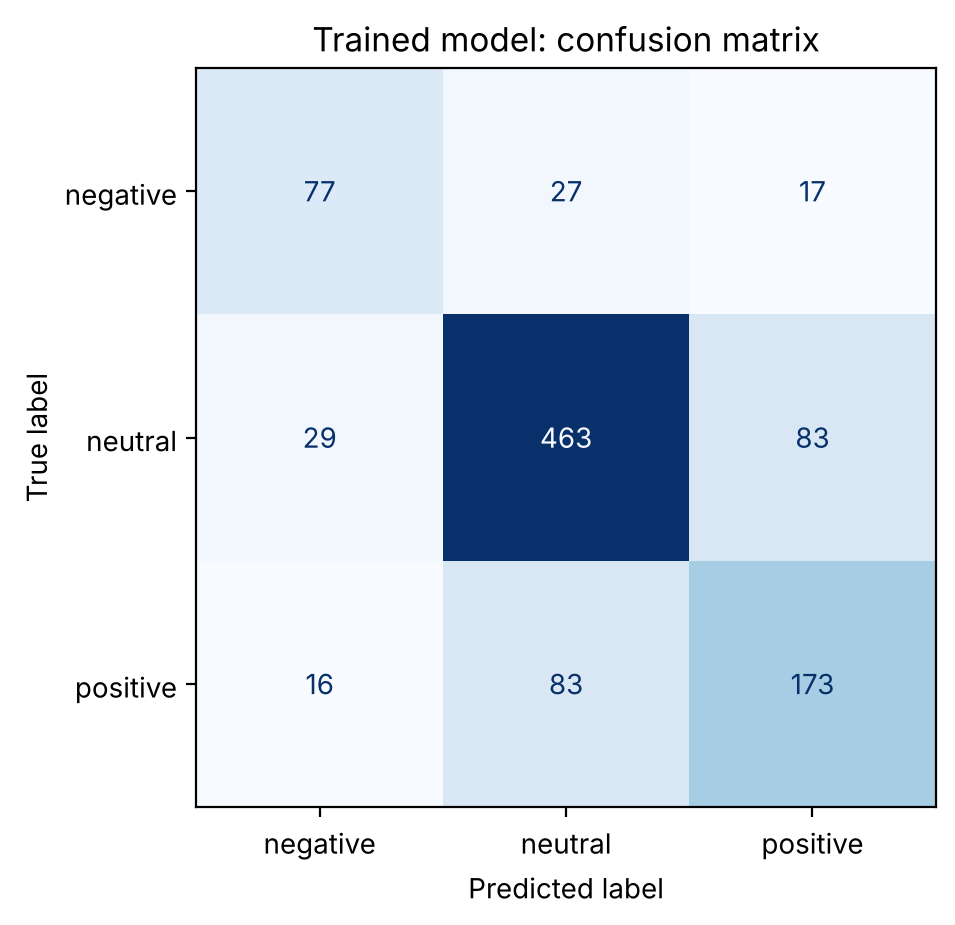

In [7]:
hi = test.text.isin(all_agree)
print(f"Accuracy on the {hi.sum()} test sentences that every annotator agreed on: {accuracy_score(test.label[hi], pred[hi.values]):.1%}")
ConfusionMatrixDisplay(confusion_matrix(test.label, pred, labels=labels), display_labels=labels).plot(cmap="Blues", colorbar=False)
plt.title("Trained model: confusion matrix"); plt.show()

## 4. What did the model learn?

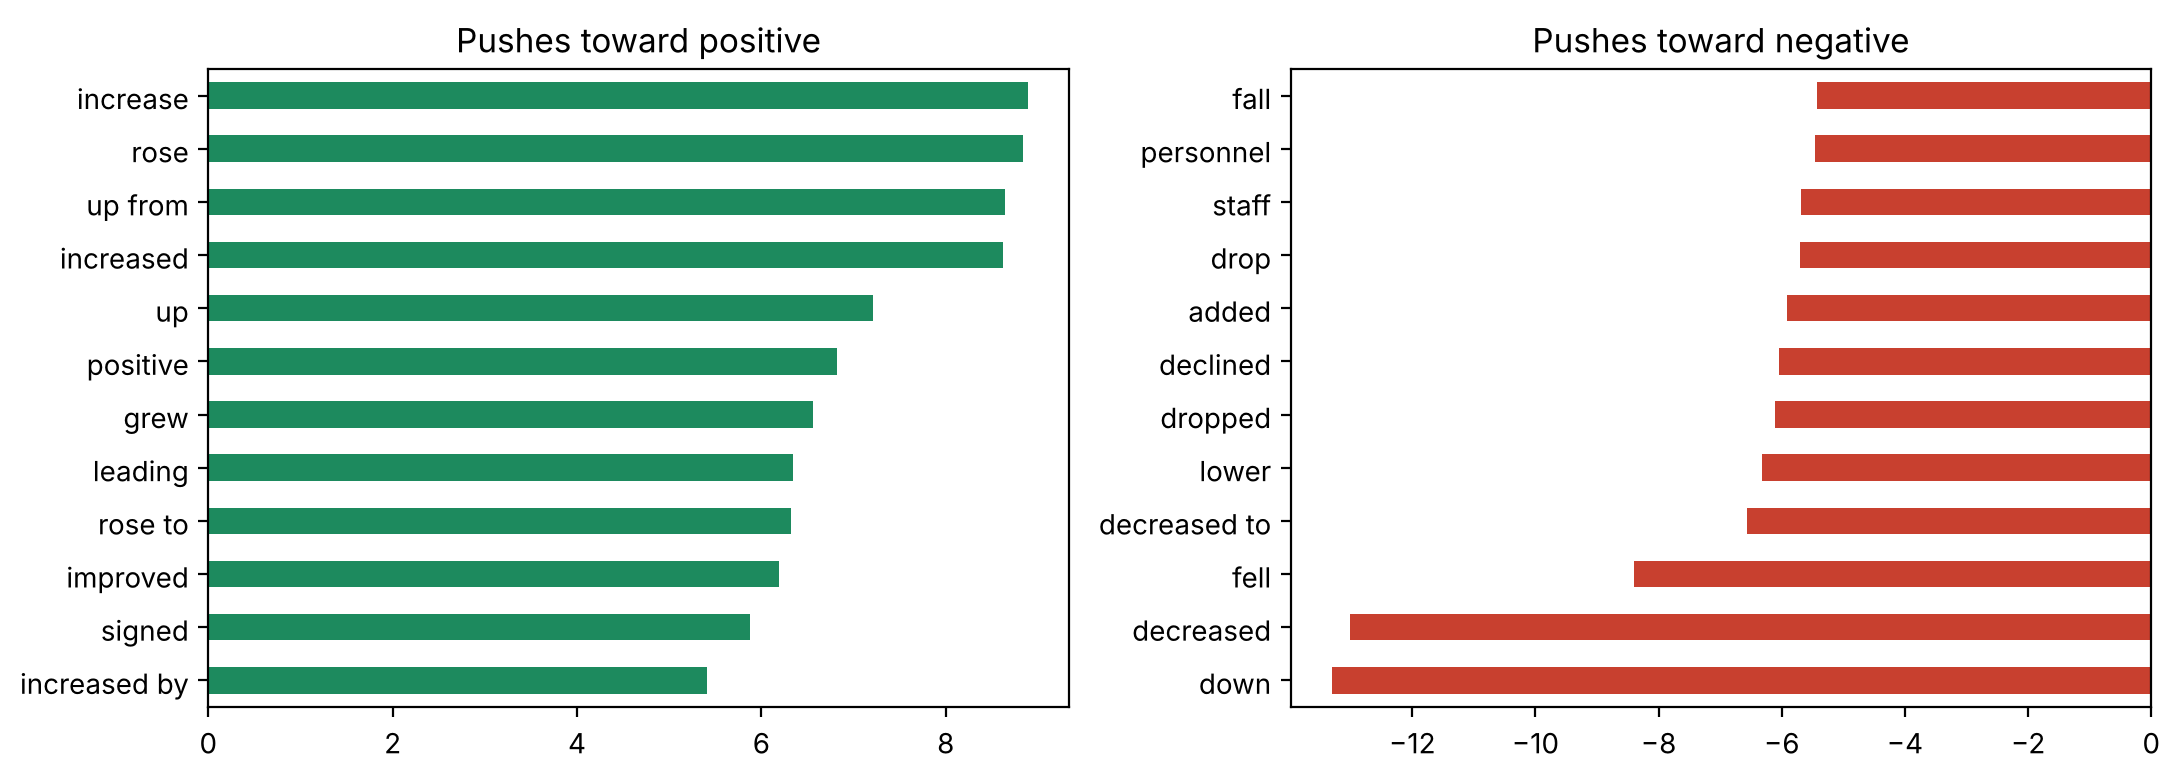

In [8]:
coef = pd.DataFrame(clf.coef_.T, index=vec.get_feature_names_out(), columns=clf.classes_)
tone = (coef.positive - coef.negative).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tone.tail(12).plot.barh(ax=ax[0], color="#1d8a5e", title="Pushes toward positive")
tone.head(12).plot.barh(ax=ax[1], color="#c8402f", title="Pushes toward negative")
plt.tight_layout(); plt.show()

*Staff* and *personnel* lean negative because in this dataset they mostly appear in layoff news. The model learns correlations, not meaning.

## 5. Score your own headlines

In [9]:
headlines = ["Chipmaker's quarterly profit jumps 40% as AI demand lifts sales",
             "Retailer cuts full-year outlook after holiday sales fall short",
             "Operating loss narrowed to $12 million from $30 million a year earlier"]   # written for testing, not real news
probs = clf.predict_proba(vec.transform(headlines))
pd.DataFrame(probs, columns=clf.classes_, index=headlines).round(2)

,negative,neutral,positive
Chipmaker's quarterly profit jumps 40% as AI demand lifts sales,0.10,0.05,0.85
Retailer cuts full-year outlook after holiday sales fall short,0.94,0.05,0.01
Operating loss narrowed to $12 million from $30 million a year earlier,0.08,0.03,0.89


## 6. Optional: live headlines and FinBERT (run in Colab)
Set `LIVE = True` to pull recent headlines for a watchlist with `yfinance`, score them with the model above, and compare against **FinBERT** (`ProsusAI/finbert`), a language model trained on financial text. This needs internet access to Yahoo Finance and Hugging Face, so it's off by default.

In [10]:
LIVE = False
if LIVE:
    !pip -q install yfinance transformers
    import yfinance as yf
    from transformers import pipeline
    finbert = pipeline("text-classification", model="ProsusAI/finbert")
    rows = []
    for tk in ["000660.KS", "NVDA", "MS", "JPM"]:          # SK hynix, Nvidia, Morgan Stanley, JPMorgan
        for item in (yf.Ticker(tk).news or [])[:10]:
            title = item.get("content", {}).get("title") or item.get("title")
            if title:
                rows.append({"ticker": tk, "headline": title, "my_model": clf.predict(vec.transform([title]))[0],
                             "finbert": finbert(title)[0]["label"]})
    live = pd.DataFrame(rows)
    display(live)
    print("Agreement with FinBERT:", (live.my_model == live.finbert).mean().round(2))

## Takeaways
1. Generic and even finance-specific **dictionaries don't beat guessing "neutral"** on accuracy for this kind of news text.
2. A simple **trained model reaches about 74% accuracy** (macro F1 0.69), and about 87% on sentences the annotators all agreed on.
3. Most mistakes are **neutral vs. positive** confusions. Negative news is the easiest class to separate.

## Limitations and next steps
- The training sentences are 2000s news about Finnish companies, so US headlines are out of domain.
- A bag-of-words model misses negation and context. FinBERT (section 6) is the natural upgrade.
- Tone isn't returns. The next step is an event study: do stocks move after strongly negative headlines?